# Klasifikasi Segmen Transaksi & Deteksi Anomali Nasabah (Classification)

## Tujuan Proyek
Melatih model *supervised learning* (**Decision Tree** dan **Random Forest**) menggunakan data berlabel dari tahap clustering (`data_clustering_clean.csv`). Model terbaik akan disimpan untuk memprediksi segmen transaksi baru secara otomatis pada dashboard Streamlit.

---

# 1. Import Library & Muat Data
Siapkan library pemodelan klasifikasi dan muat dataset hasil clustering.

In [1]:
# Hapus tanda # jika library belum terinstal
# %pip install pandas matplotlib seaborn scikit-learn joblib

import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import joblib

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

print("Library siap.")

Library siap.


## 1.1 Muat & Cek Dataset Berlabel
Baca `data_clustering_clean.csv`, pastikan tidak ada data kosong, dan cek sebaran kelas target (`Cluster`).

In [2]:
data_path = 'data_clustering_clean.csv'
df = pd.read_csv(data_path)

print(f"Ukuran data: {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"Total missing values: {df.isnull().sum().sum()}\n")

print("=== Distribusi Kelas Target (Cluster) ===")
target_dist = pd.DataFrame({
    'Nama Segmen': df.groupby('Cluster')['Segment_Name'].first(),
    'Jumlah': df['Cluster'].value_counts().sort_index(),
    'Persentase (%)': df['Cluster'].value_counts(normalize=True).sort_index() * 100
})
display(target_dist)

df.head()

Ukuran data: 2516 baris, 12 kolom
Total missing values: 0

=== Distribusi Kelas Target (Cluster) ===


,Nama Segmen,Jumlah,Persentase (%)
Cluster,,,
0,0 - Nasabah Mapan Konservatif,1596,63.43
1,1 - Nasabah Muda Aktif,827,32.87
2,2 - Transaksi Berisiko (Anomali Login),93,3.70


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Balance_Ratio,Cluster,Segment_Name
0,14.09,Debit,San Diego,ATM,70.00,Doctor,81.00,1.00,5112.21,0.00,0,0 - Nasabah Mapan Konservatif
1,376.24,Debit,Houston,ATM,68.00,Doctor,141.00,1.00,13758.91,0.03,0,0 - Nasabah Mapan Konservatif
2,126.29,Debit,Mesa,Online,19.00,Student,56.00,1.00,1122.35,0.11,1,1 - Nasabah Muda Aktif
3,184.50,Debit,Raleigh,Online,26.00,Student,25.00,1.00,8569.06,0.02,0,0 - Nasabah Mapan Konservatif
4,13.45,Credit,Atlanta,Online,45.00,Student,198.00,1.00,7429.40,0.00,0,0 - Nasabah Mapan Konservatif


## 1.2 Pemisahan Fitur Prediktor (`X`) dan Target (`y`)
Tetapkan `Cluster` sebagai target `y`. Buang dua kolom dari fitur `X`:
1. **`Segment_Name`**: teks turunan langsung dari `Cluster` (wajib dihapus agar tidak terjadi *data leakage*).
2. **`Location`**: berisi `43` nama kota yang tidak dipakai saat pembentukan cluster dan hanya menambah *noise* dimensi tinggi jika di-encode.

In [3]:
y = df['Cluster']
X = df.drop(columns=['Cluster', 'Segment_Name', 'Location'])

numerical_cols = X.select_dtypes(include='number').columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'string']).columns.tolist()

print(f"Target (y): Cluster ({y.nunique()} kelas)")
print(f"Fitur (X): {X.shape[1]} kolom")
print(f"- Numerik ({len(numerical_cols)}): {numerical_cols}")
print(f"- Kategorikal ({len(categorical_cols)}): {categorical_cols}")

X.head()

Target (y): Cluster (3 kelas)
Fitur (X): 9 kolom
- Numerik (6): ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance', 'Balance_Ratio']
- Kategorikal (3): ['TransactionType', 'Channel', 'CustomerOccupation']


,TransactionAmount,TransactionType,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Balance_Ratio
0,14.09,Debit,ATM,70.00,Doctor,81.00,1.00,5112.21,0.00
1,376.24,Debit,ATM,68.00,Doctor,141.00,1.00,13758.91,0.03
2,126.29,Debit,Online,19.00,Student,56.00,1.00,1122.35,0.11
3,184.50,Debit,Online,26.00,Student,25.00,1.00,8569.06,0.02
4,13.45,Credit,Online,45.00,Student,198.00,1.00,7429.40,0.00


---

# 2. Data Splitting & One-Hot Encoding
1. **Split `80:20` dengan `stratify=y`**: bagi data sebelum encoding agar tidak terjadi *data leakage*, dan jaga proporsi Cluster 2 (`3.70%`) tetap seimbang di data latih maupun uji.
2. **One-Hot Encoding**: ubah `3` fitur teks (`TransactionType`, `Channel`, `CustomerOccupation`) menjadi kolom biner (`0`/`1`) memakai `ColumnTransformer`. Fitur numerik tidak perlu di-scale karena *Decision Tree* dan *Random Forest* tidak sensitif terhadap skala angka.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Data latih: {X_train.shape[0]} baris")
print(f"Data uji: {X_test.shape[0]} baris\n")

split_check = pd.DataFrame({
    'Latih (Jumlah)': y_train.value_counts().sort_index(),
    'Latih (%)': y_train.value_counts(normalize=True).sort_index() * 100,
    'Uji (Jumlah)': y_test.value_counts().sort_index(),
    'Uji (%)': y_test.value_counts(normalize=True).sort_index() * 100
})
print("=== Perbandingan Proporsi Kelas (Stratified Split) ===")
display(split_check)

Data latih: 2012 baris
Data uji: 504 baris

=== Perbandingan Proporsi Kelas (Stratified Split) ===


,Latih (Jumlah),Latih (%),Uji (Jumlah),Uji (%)
Cluster,,,,
0,1276,63.42,320,63.49
1,661,32.85,166,32.94
2,75,3.73,18,3.57


## 2.1 Setup Preprocessor (`ColumnTransformer`)
Bungkus proses encoding dalam `ColumnTransformer` agar nanti mudah digabung ke `Pipeline` bersama model klasifikasi. `fit` hanya dilakukan pada `X_train`.

In [5]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Preview hasil encoding (fit hanya pada X_train)
X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print(f"Ukuran X_train setelah encoding: {X_train_enc.shape}")
print(f"Ukuran X_test setelah encoding: {X_test_enc.shape}")
print(f"Total fitur ({len(feature_names)}): {list(feature_names)}\n")

pd.DataFrame(X_train_enc, columns=feature_names).head()

Ukuran X_train setelah encoding: (2012, 15)
Ukuran X_test setelah encoding: (504, 15)
Total fitur (15): ['num__TransactionAmount', 'num__CustomerAge', 'num__TransactionDuration', 'num__LoginAttempts', 'num__AccountBalance', 'num__Balance_Ratio', 'cat__TransactionType_Credit', 'cat__TransactionType_Debit', 'cat__Channel_ATM', 'cat__Channel_Branch', 'cat__Channel_Online', 'cat__CustomerOccupation_Doctor', 'cat__CustomerOccupation_Engineer', 'cat__CustomerOccupation_Retired', 'cat__CustomerOccupation_Student']



,num__TransactionAmount,num__CustomerAge,num__TransactionDuration,num__LoginAttempts,num__AccountBalance,num__Balance_Ratio,cat__TransactionType_Credit,cat__TransactionType_Debit,cat__Channel_ATM,cat__Channel_Branch,cat__Channel_Online,cat__CustomerOccupation_Doctor,cat__CustomerOccupation_Engineer,cat__CustomerOccupation_Retired,cat__CustomerOccupation_Student
0,209.03,55.00,126.00,1.00,8359.50,0.03,0.00,1.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00
1,83.16,61.00,177.00,1.00,3065.87,0.03,0.00,1.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00
2,416.55,33.00,73.00,1.00,922.96,0.45,0.00,1.00,0.00,0.00,1.00,0.00,1.00,0.00,0.00
3,422.81,28.00,193.00,1.00,1929.28,0.22,0.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00
4,870.30,51.00,229.00,1.00,3688.98,0.24,0.00,1.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00


---

# 3. Pelatihan Model & Evaluasi
Bandingkan dua algoritma dalam `Pipeline` (menggabungkan `preprocessor` dan model agar bebas *data leakage*):
1. **Decision Tree**: model *baseline* sederhana yang mudah diinterpretasi.
2. **Random Forest**: gabungan banyak *Decision Tree* yang lebih stabil terhadap *overfitting*.

Evaluasi dilakukan lewat **5-fold Stratified Cross-Validation** pada `X_train` untuk mengukur stabilitas model, lalu diuji sekali pada `X_test`. Metrik utama adalah **Macro F1-Score** agar performa pada kelas minoritas (`Cluster 2`) ikut dinilai adil.

In [6]:
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
trained_models = {}
predictions = {}
eval_rows = []

for name, clf in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])

    # 5-fold CV pada data latih
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    trained_models[name] = pipe
    predictions[name] = y_pred

    eval_rows.append({
        'Model': name,
        'CV Macro F1 (Mean)': cv_scores.mean(),
        'CV Macro F1 (Std)': cv_scores.std(),
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'Test Precision (Macro)': precision_score(y_test, y_pred, average='macro'),
        'Test Recall (Macro)': recall_score(y_test, y_pred, average='macro'),
        'Test F1 (Macro)': f1_score(y_test, y_pred, average='macro')
    })

results_df = pd.DataFrame(eval_rows)
print("=== Perbandingan Performa Model ===")
display(results_df.assign(**{
    col: results_df[col].map('{:.4f}'.format)
    for col in results_df.columns if col != 'Model'
}))

=== Perbandingan Performa Model ===


,Model,CV Macro F1 (Mean),CV Macro F1 (Std),Test Accuracy,Test Precision (Macro),Test Recall (Macro),Test F1 (Macro)
0,Decision Tree,0.9765,0.0090,0.9782,0.9837,0.9827,0.9832
1,Random Forest,0.9797,0.0033,0.9782,0.9856,0.9808,0.9831


## 3.1 Classification Report & Confusion Matrix
Cek akurasi prediksi per segmen, khususnya *Recall* pada `Cluster 2` (transaksi berisiko) agar tidak ada anomali yang lolos.

=== Classification Report: Decision Tree ===
              precision    recall  f1-score   support

   Cluster 0     0.9813    0.9844    0.9828       320
   Cluster 1     0.9697    0.9639    0.9668       166
   Cluster 2     1.0000    1.0000    1.0000        18

    accuracy                         0.9782       504
   macro avg     0.9837    0.9827    0.9832       504
weighted avg     0.9782    0.9782    0.9782       504

=== Classification Report: Random Forest ===
              precision    recall  f1-score   support

   Cluster 0     0.9754    0.9906    0.9829       320
   Cluster 1     0.9814    0.9518    0.9664       166
   Cluster 2     1.0000    1.0000    1.0000        18

    accuracy                         0.9782       504
   macro avg     0.9856    0.9808    0.9831       504
weighted avg     0.9782    0.9782    0.9781       504



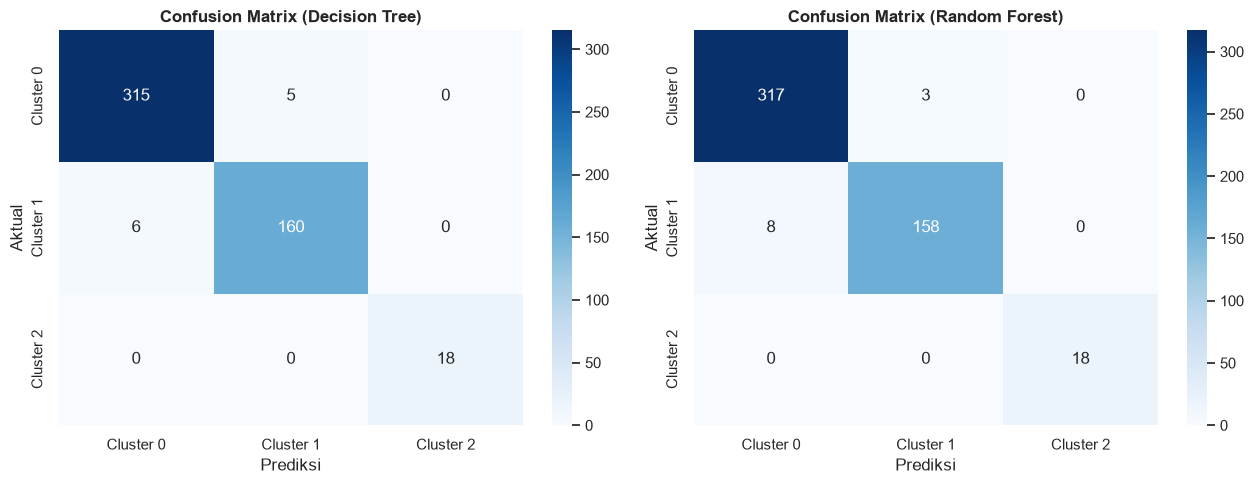

In [7]:
class_labels = ['Cluster 0', 'Cluster 1', 'Cluster 2']

for name, y_pred in predictions.items():
    print(f"=== Classification Report: {name} ===")
    print(classification_report(y_test, y_pred, target_names=class_labels, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=class_labels, yticklabels=class_labels, ax=ax
    )
    ax.set_title(f'Confusion Matrix ({name})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')

plt.tight_layout()
plt.show()

---

# 4. Model Final, Feature Importance, & Ekspor Model
**Random Forest** dipilih sebagai model final karena punya `CV Macro F1` lebih tinggi (`0.9797` vs `0.9765`) dan standar deviasi jauh lebih kecil (`0.0033` vs `0.0090`), sekaligus mendeteksi `100%` transaksi berisiko (`Cluster 2`).

=== Top 10 Fitur Paling Berpengaruh (Random Forest) ===


,Fitur,Importance
0,AccountBalance,0.2560
1,CustomerAge,0.2529
2,CustomerOccupation_Student,0.1505
3,LoginAttempts,0.1099
4,Balance_Ratio,0.1029
5,TransactionAmount,0.0349
6,CustomerOccupation_Retired,0.0307
7,TransactionDuration,0.0252
8,CustomerOccupation_Doctor,0.0133
9,CustomerOccupation_Engineer,0.0100


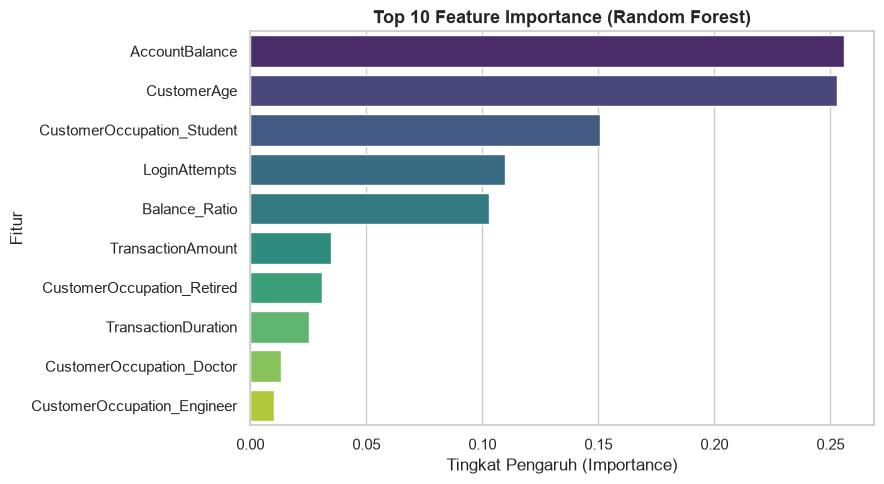

In [8]:
best_model = trained_models['Random Forest']

raw_names = best_model.named_steps['preprocessor'].get_feature_names_out()
clean_names = [name.replace('num__', '').replace('cat__', '') for name in raw_names]
importances = best_model.named_steps['classifier'].feature_importances_

feat_imp = pd.DataFrame({
    'Fitur': clean_names,
    'Importance': importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print("=== Top 10 Fitur Paling Berpengaruh (Random Forest) ===")
display(feat_imp.head(10).assign(Importance=lambda d: d['Importance'].map('{:.4f}'.format)))

plt.figure(figsize=(9, 5))
sns.barplot(data=feat_imp.head(10), x='Importance', y='Fitur', palette='viridis')
plt.title('Top 10 Feature Importance (Random Forest)', fontsize=13, fontweight='bold')
plt.xlabel('Tingkat Pengaruh (Importance)')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

## 4.1 Simulasi Prediksi Transaksi Baru
Uji `best_model` memakai `3` contoh input mentah (mewakili profil tiap segmen) untuk memastikan `Pipeline` siap menerima input langsung dari form Streamlit.

In [9]:
cluster_name_map = {
    0: '0 - Nasabah Mapan Konservatif',
    1: '1 - Nasabah Muda Aktif',
    2: '2 - Transaksi Berisiko (Anomali Login)'
}

sample_tx = pd.DataFrame([
    # Contoh 1: Nasabah senior, saldo besar, login normal
    {'TransactionAmount': 250.0, 'TransactionType': 'Debit', 'Channel': 'Branch',
     'CustomerAge': 58, 'CustomerOccupation': 'Retired', 'TransactionDuration': 110,
     'LoginAttempts': 1, 'AccountBalance': 8500.0},
    # Contoh 2: Mahasiswa, saldo kecil, transaksi cukup besar
    {'TransactionAmount': 420.0, 'TransactionType': 'Debit', 'Channel': 'Online',
     'CustomerAge': 22, 'CustomerOccupation': 'Student', 'TransactionDuration': 95,
     'LoginAttempts': 1, 'AccountBalance': 950.0},
    # Contoh 3: Upaya login berulang lewat kanal Online
    {'TransactionAmount': 310.0, 'TransactionType': 'Debit', 'Channel': 'Online',
     'CustomerAge': 45, 'CustomerOccupation': 'Doctor', 'TransactionDuration': 140,
     'LoginAttempts': 4, 'AccountBalance': 5200.0}
])
sample_tx['Balance_Ratio'] = sample_tx['TransactionAmount'] / sample_tx['AccountBalance']

pred_classes = best_model.predict(sample_tx)
pred_probs = best_model.predict_proba(sample_tx).max(axis=1) * 100

sim_result = sample_tx[['TransactionAmount', 'CustomerAge', 'AccountBalance', 'LoginAttempts', 'Balance_Ratio']].copy()
sim_result['Prediksi Segmen'] = [cluster_name_map[c] for c in pred_classes]
sim_result['Confidence (%)'] = pred_probs

print("=== Hasil Simulasi Prediksi Transaksi Baru ===")
display(sim_result)

=== Hasil Simulasi Prediksi Transaksi Baru ===


,TransactionAmount,CustomerAge,AccountBalance,LoginAttempts,Balance_Ratio,Prediksi Segmen,Confidence (%)
0,250.00,58,8500.00,1,0.03,0 - Nasabah Mapan Konservatif,100.00
1,420.00,22,950.00,1,0.44,1 - Nasabah Muda Aktif,100.00
2,310.00,45,5200.00,4,0.06,2 - Transaksi Berisiko (Anomali Login),90.00


## 4.2 Simpan Pipeline Model Final
Ekspor `best_model` (`ColumnTransformer` + `RandomForestClassifier`) dalam satu file `.joblib` agar siap dipakai pada **Fase 3 (Dashboard Interaktif Streamlit)**.

In [10]:
model_path = 'rf_classifier_pipeline.joblib'
joblib.dump(best_model, model_path)

loaded_model = joblib.load(model_path)
verify_acc = accuracy_score(y_test, loaded_model.predict(X_test))

print("File tersimpan:")
print(f"- {model_path}")
print(f"Verifikasi muat ulang (Test Accuracy): {verify_acc:.4f}")

File tersimpan:
- rf_classifier_pipeline.joblib
Verifikasi muat ulang (Test Accuracy): 0.9782
